# Kimuntu AI — Week 1

## Baseline Legal Text Classification

- **Student:** Nassejje Racheal (BDSAI)
- **Student ID:** 237-415
- **Course:** Advanced AI and Robotics
- **Project Partner:** Kimuntu Power Inc. (via Riipen)
- **Role:** Group Coordinator

**Goal:** build a baseline classifier that reads a user's legal question, written in everyday language, and predicts which area of law it belongs to.

> Sections 1 (Problem Understanding) and 2 (System Design) are in the accompanying report. This notebook covers Sections 3 to 6: dataset preparation, the baseline model, evaluation and interpretation.

In [ ]:

# Hugging Face is a main public hub for machine learning, AI resources
#  pre-trained models,datasets and demo apps.

# it has a library called `datasets` where u can get datasets from
# that hub straight into memory, with no manual download or unzipping.

# Provenance of the data used in this notebook:
#   The data originates from Reddit's r/legaladvice community. It was
#   collected, labelled and published as a research dataset by Li et al.
#   (2022), and we downloaded it from the Hugging Face Hub.

# -q = quiet, so the installation logs do not fill the notebook.

!pip install datasets -q

## 3. Dataset Preparation

Company data is not yet available, so a public proxy dataset is used.

`jonathanli/legal-advice-reddit` contains posts from Reddit's r/legaladvice
community, where users describe real legal problems in their own words.
Each post carries a single community-assigned topic label, making it
directly suitable for single-label text classification.

The dataset ships with its own train / validation / test splits, which we
retain so that no evaluation data leaks into training.

In [ ]:
# pandas: the table library. "pd" is the standard nickname everyone uses.
import pandas as pd

# Take just one function out of the Hugging Face datasets library.
from datasets import load_dataset

# One line does four things: finds the dataset on the Hugging Face Hub,
# downloads it, caches it locally (so re-running is instant), and returns it.
# The name reads author/dataset-name.
# inside it - ds["train"], ds["validation"] and ds["test"].
ds = load_dataset("jonathanli/legal-advice-reddit")

# Print the structure BEFORE converting to pandas: which splits exist,
# what columns each has, and how many rows. Always inspect the shape of
# data before working with it - you cannot clean what you have not looked at.
print(ds)

README.md:   0%|          | 0.00/1.54k [00:00<?, ?B/s]

train.jsonl: reconstructing file:   0%|          |  0.00B / 15.6MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl: reconstructing file:   0%|          |  0.00B / 16.0MB            

validation.jsonl: downloading bytes:           |  0.00B            

...

test.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/9887 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/9887 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/79136 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['created_utc', 'full_link', 'id', 'body', 'title', 'text_label', 'flair_label'],
        num_rows: 9887
    })
    validation: Dataset({
        features: ['created_utc', 'full_link', 'id', 'body', 'title', 'text_label', 'flair_label'],
        num_rows: 9887
    })
    test: Dataset({
        features: ['created_utc', 'full_link', 'id', 'body', 'title', 'text_label', 'flair_label'],
        num_rows: 79136
    })
})


### 3.1 Converting to pandas and inspecting

The dataset ships as a `DatasetDict` with three splits. We convert each to a
pandas DataFrame for inspection.

Note the unusual split sizes: train 9,887, validation 9,887, test 79,136.
The test split is substantially larger than the training split. The supplied
splits are retained so that results remain comparable with the published
benchmark, and because a large test set yields a more reliable performance
estimate.

In [ ]:
# Pull each split out of the DatasetDict by name and convert it to a
# pandas DataFrame.
train_df = ds["train"].to_pandas()
val_df   = ds["validation"].to_pandas()
test_df  = ds["test"].to_pandas()

# .shape returns (rows, columns) for each table
print("train:", train_df.shape)
print("val:  ", val_df.shape)
print("test: ", test_df.shape)

# Verify the number of categories from the data itself, rather than
# relying on the dataset's documentation page.
print("\nCategories:", train_df["text_label"].nunique())
print(sorted(train_df["text_label"].unique()))

# Look at the first five training examples.
train_df[["title", "body", "text_label"]].head()

train: (9887, 7)
val:   (9887, 7)
test:  (79136, 7)

Categories: 11
['business', 'contract', 'criminal', 'digital', 'driving', 'employment', 'family', 'housing', 'insurance', 'school', 'wills']


,title,body,text_label
0,My former employer fired everyone when they ha...,The title says most of it. I just heard back f...,employment
1,Landlord is updating snow removal policies and...,"In Maine, my landlord (commercial property man...",housing
2,Ceiling collapse,"Hello all, I moved into my apartment in August...",housing
3,Need Help with Rescheduling 2020 Wedding,"My wedding date is September 6th, 2020. Due to...",contract
4,TX Emergency Advice,So not 100% sure where this goes but I figured...,housing


### 3.2 Class distribution

Before training anything we check how many posts fall into each of the eleven
categories.

This matters for two reasons:

1. **Accuracy can mislead.** If one category dominates, a model that always
   predicts that single category scores well on accuracy while being useless.
2. **Rare classes are learned poorly.** A category with very few training
   examples gives the model little to learn from, so we expect weaker recall
   on those classes. Knowing this in advance tells us what to look for in the
   confusion matrix later.

`value_counts()` gives raw counts; adding `normalize=True` converts them to
proportions, which we multiply by 100 to read as percentages.

In [ ]:
# How many training posts belong to each category
print("Counts:")
counts = train_df["text_label"].value_counts()
print(counts)

# The same figures as percentages of the training set
print("\nPercentages:")
print(counts.div(len(train_df)).mul(100).round(2))

# State the imbalance explicitly: the largest class fixes the score a
# no-learning baseline would achieve, and the ratio tells us how much
# less training signal the smallest class receives.
print(f"\nLargest class : {counts.idxmax()} ({counts.max()} posts)")
print(f"Smallest class: {counts.idxmin()} ({counts.min()} posts)")
print(f"Imbalance ratio: {counts.max() / counts.min():.1f} : 1")

Counts:
text_label
housing       2387
employment    1592
family        1193
driving        942
criminal       868
business       576
digital        527
contract       517
school         432
insurance      431
wills          422
Name: count, dtype: int64

Percentages:
text_label
housing       24.14
employment    16.10
family        12.07
driving        9.53
criminal       8.78
business       5.83
digital        5.33
contract       5.23
school         4.37
insurance      4.36
wills          4.27
Name: count, dtype: float64

Largest class : housing (2387 posts)
Smallest class: wills (422 posts)
Imbalance ratio: 5.7 : 1


### 3.3 Constructing the model input

Each post has two text fields: a short `title` and a longer `body`. Both carry
useful signal — the title often states the problem directly, while the body
gives detail so we join them into a single `text` column, which becomes the
input to the classifier.

Three preparation decisions, recorded here for the report:

1. **Missing values.** `fillna("")` replaces any missing title or body with an
   empty string, so joining them never produces the literal text "nan".
2. **Whitespace.** `.str.strip()` removes leading and trailing spaces created
   by the join.
3. **Duplicates.** We count repeated posts. A duplicate appearing in both the
   training and evaluation sets would let the model recognise text it has
   already memorised, inflating the reported score. This is a form of data
   leakage.

We keep only the two columns the model needs: `text` and `text_label`.

In [ ]:
def prepare(df):
    """Join title and body into one text column, keeping only what the model needs."""
    out = df.copy()

    # Replace missing values so the join cannot produce "nan"
    out["title"] = out["title"].fillna("")
    out["body"]  = out["body"].fillna("")

    # Combine the two fields into the model's single input field
    out["text"] = (out["title"] + " " + out["body"]).str.strip()

    # Keep only the input and the target
    return out[["text", "text_label"]]

# Apply the same preparation to all three splits
train_df = prepare(train_df)
val_df   = prepare(val_df)
test_df  = prepare(test_df)

# Data-quality checks
print("Empty texts in train:", (train_df["text"] == "").sum())
print("Duplicate texts in train:", train_df["text"].duplicated().sum())

train_df.head()

Empty texts in train: 0
Duplicate texts in train: 31


,text,text_label
0,My former employer fired everyone when they ha...,employment
1,Landlord is updating snow removal policies and...,housing
2,"Ceiling collapse Hello all, I moved into my ap...",housing
3,Need Help with Rescheduling 2020 Wedding My we...,contract
4,TX Emergency Advice So not 100% sure where thi...,housing


### 3.4 Removing duplicates

Two kinds of duplication matter:

1. **Within a split** — the same post appearing twice in training gives that
   example double weight for no reason.
2. **Across splits** — the same post appearing in both training and
   evaluation. This is the serious case: the model would be tested on text it
   has already memorised, inflating the reported score. This is data leakage.

We remove within-split duplicates first, then drop from validation and test
any post whose text already appears in training. Training is treated as the
authoritative split so that no training data is discarded.

In [ ]:

# 1. Remove duplicates WITHIN each split

# Mild problem: a repeated post is simply counted twice during training,
# giving that one example double weight for no reason.

# Record the sizes first so we can report what was removed.
before = len(train_df), len(val_df), len(test_df)

# subset="text" means: treat two rows as duplicates if their TEXT matches.
# reset_index(drop=True) renumbers the rows 0,1,2... after removal;
# drop=True throws away the old numbering instead of keeping it as a column.
train_df = train_df.drop_duplicates(subset="text").reset_index(drop=True)
val_df   = val_df.drop_duplicates(subset="text").reset_index(drop=True)
test_df  = test_df.drop_duplicates(subset="text").reset_index(drop=True)

print("Within-split duplicates removed:")
print(f"  train: {before[0]} -> {len(train_df)}")
print(f"  val:   {before[1]} -> {len(val_df)}")
print(f"  test:  {before[2]} -> {len(test_df)}")

# ---------------------------------------------------------------
# 2. Remove ACROSS-split overlap - this is the serious case
# ---------------------------------------------------------------
# If the same post sits in both training and test, the model would be
# evaluated on text it has already memorised. The reported score would
# measure recall of memory, not ability to generalise. This is data leakage.

# A set gives fast membership checking: "is this text in training?"
train_texts = set(train_df["text"])

# Measure the overlap BEFORE removing it, so the notebook records
# whether leakage existed rather than silently fixing it.
val_overlap  = val_df["text"].isin(train_texts).sum()
test_overlap = test_df["text"].isin(train_texts).sum()
print(f"\nOverlap with training -> val: {val_overlap}, test: {test_overlap}")

# ~ means NOT. So this keeps only the rows NOT found in training.
# Training is treated as authoritative: we drop from the evaluation sets
# rather than from training, so no training data is lost.
val_df  = val_df[~val_df["text"].isin(train_texts)].reset_index(drop=True)
test_df = test_df[~test_df["text"].isin(train_texts)].reset_index(drop=True)

print("\nFinal sizes:")
print("  train:", len(train_df))
print("  val:  ", len(val_df))
print("  test: ", len(test_df))
...

Within-split duplicates removed:
  train: 9887 -> 9856
  val:   9887 -> 9885
  test:  79136 -> 79074

Overlap with training -> val: 0, test: 0

Final sizes:
  train: 9856
  val:   9885
  test:  79074


Ellipsis

### 3.5 Final class distribution after cleaning

The class distribution reported in Section 3.2 was computed before duplicate
removal. We recompute it on the final training set so that the figures quoted
in the report match the data the model was actually trained on.

In [ ]:
print("Final training set size:", len(train_df))
print()
print("Counts:")
print(train_df["text_label"].value_counts())
print()
print("Percentages:")
print(train_df["text_label"].value_counts(normalize=True).mul(100).round(2))

Final training set size: 9856

Counts:
text_label
housing       2374
employment    1581
family        1191
driving        940
criminal       868
business       576
digital        526
contract       517
insurance      431
school         430
wills          422
Name: count, dtype: int64

Percentages:
text_label
housing       24.09
employment    16.04
family        12.08
driving        9.54
criminal       8.81
business       5.84
digital        5.34
contract       5.25
insurance      4.37
school         4.36
wills          4.28
Name: proportion, dtype: float64


## 4. Baseline Text Classification Model

Two models are built and compared.

**The baseline** always predicts the single most frequent training class
(`housing`). It learns nothing from the text at all. Its purpose is to
provide a floor: any genuine model must beat it, otherwise the learning
has added no value. Scikit-learn provides this as `DummyClassifier`.

**The classifier** combines two components inside a single pipeline:

- **TF-IDF** converts text into numbers. Term Frequency counts how often a
  word appears in a document; Inverse Document Frequency reduces the weight
  of words appearing in most documents. The result gives
  high weight to words that are frequent in one document but rare across the
  corpus — exactly the words that identify a category, such as "landlord"
  or "eviction".

- **Logistic Regression** learns, for each of the eleven categories, which
  words push a post towards or away from that category, and outputs the
  most likely category.

Both steps are wrapped in a `Pipeline`. This matters: the pipeline fits the
TF-IDF vocabulary on the training data **only**, preventing vocabulary from
the evaluation sets from influencing training — a form of data leakage.

In [ ]:
from sklearn.dummy import DummyClassifier           # the no-learning baseline
from sklearn.feature_extraction.text import TfidfVectorizer  # text -> numbers
from sklearn.linear_model import LogisticRegression          # the classifier
from sklearn.pipeline import Pipeline               # chains steps together


# Separate inputs (X) from targets (y)
# X is what the model SEES: the text of each post.
# y is what the model must PREDICT: one of the eleven categories.
# By convention X is capital (a table of features) and y lowercase (one column).
X_train, y_train = train_df["text"], train_df["text_label"]
X_val,   y_val   = val_df["text"],   val_df["text_label"]
X_test,  y_test  = test_df["text"],  test_df["text_label"]


# Baseline: always predict the most frequent class

# This model never reads the text. During fit() it learns one fact -
# which label is commonest in training - and answers that every time.
# It exists to give us a floor: a trained model that cannot beat this
# has added nothing. Here that floor is "housing", about 24% of posts.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)


# The real model: TF-IDF features + Logistic Regression

# A Pipeline is an ordered list of named steps. Calling fit() on the
# pipeline fits every step in sequence, and - crucially - fits them on
# the TRAINING data only. Fitting TF-IDF on the full corpus would let
# vocabulary from the evaluation sets influence training: data leakage.
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,      # "Landlord" and "landlord" become one word
        min_df=2,            # ignore words appearing in only one post (noise)
        max_features=50000,  # cap the vocabulary; never reached here (16,410)
        stop_words="english" # drop "the", "is", "my" - no category signal
    )),
    ("clf", LogisticRegression(
        max_iter=1000,       # enough iterations for the solver to converge
        n_jobs=-1            # -1 means use all available CPU cores
    )),
])

# One call trains the whole chain: TF-IDF learns the vocabulary,
# then logistic regression learns the word weights for each category.
model.fit(X_train, y_train)

print("Baseline trained.")
print("Model trained.")

# The vocabulary is every distinct word TF-IDF kept. Each one becomes
# a feature, so this number is how many features the classifier uses.
print("Vocabulary size:", len(model.named_steps["tfidf"].vocabulary_))

Baseline trained.
Model trained.
Vocabulary size: 16410


## 5. Model Evaluation

### 5.1 Validation results

The validation split is used first, so that the test split remains untouched
until a final model is selected. Two metrics are reported:

- **Accuracy** — the proportion of all posts classified correctly.
- **Macro F1** — the F1 score computed separately for each of the eleven
  classes and then averaged with equal weight. Because every class counts
  equally regardless of size, macro F1 exposes poor performance on the small
  categories that accuracy would otherwise hide.

The baseline figures establish the floor the trained model must exceed.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

def evaluate(name, fitted_model, X, y_true):
    """Print accuracy and macro F1 for a fitted model."""
    y_pred = fitted_model.predict(X)
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="macro")
    print(f"{name:<22} accuracy = {acc:.4f}   macro F1 = {f1:.4f}")
    return y_pred

print("VALIDATION SET")
print("-" * 60)
_ = evaluate("Baseline (most frequent)", baseline, X_val, y_val)
_ = evaluate("TF-IDF + LogisticReg",     model,    X_val, y_val)

VALIDATION SET
------------------------------------------------------------
Baseline (most frequent) accuracy = 0.2413   macro F1 = 0.0353
TF-IDF + LogisticReg   accuracy = 0.8247   macro F1 = 0.7626


### 5.2 Test set results

The test split has been untouched until this point. It provides the final,
unbiased estimate of how the model would perform on unseen user queries.

`classification_report` gives precision, recall and F1 for every class
individually, plus macro and weighted averages.

- **Precision** — of the posts the model labelled as a given category, what
  fraction genuinely belonged to it.
- **Recall** — of the posts that genuinely belonged to a category, what
  fraction the model found.
- **F1** — the harmonic mean of precision and recall, balancing the two.

In [ ]:
from sklearn.metrics import classification_report

print("TEST SET")
print("-" * 60)
y_pred_base  = evaluate("Baseline (most frequent)", baseline, X_test, y_test)
y_pred_model = evaluate("TF-IDF + LogisticReg",     model,    X_test, y_test)

print("\n\nPer-class report — TF-IDF + Logistic Regression")
print("=" * 60)
print(classification_report(y_test, y_pred_model, digits=3))

TEST SET
------------------------------------------------------------
Baseline (most frequent) accuracy = 0.2414   macro F1 = 0.0354
TF-IDF + LogisticReg   accuracy = 0.8215   macro F1 = 0.7607


Per-class report — TF-IDF + Logistic Regression
              precision    recall  f1-score   support

    business      0.684     0.474     0.560      4604
    contract      0.708     0.492     0.581      4134
    criminal      0.682     0.762     0.720      6946
     digital      0.676     0.657     0.666      4210
     driving      0.828     0.858     0.843      7532
  employment      0.808     0.928     0.864     12734
      family      0.870     0.907     0.888      9545
     housing      0.919     0.966     0.942     19087
   insurance      0.743     0.602     0.665      3451
      school      0.858     0.743     0.796      3455
       wills      0.905     0.788     0.843      3376

    accuracy                          0.821     79074
   macro avg      0.789     0.743     0.761     7907

### 5.3 Confusion matrix

The confusion matrix shows which categories the model confuses with which.
Rows are the true categories, columns the predicted ones. The diagonal holds
correct predictions; every off-diagonal cell is an error, and its position
tells us the nature of that error.

Values are normalised by row, so each cell reads as "of all posts truly
belonging to this category, what fraction were predicted as that one".

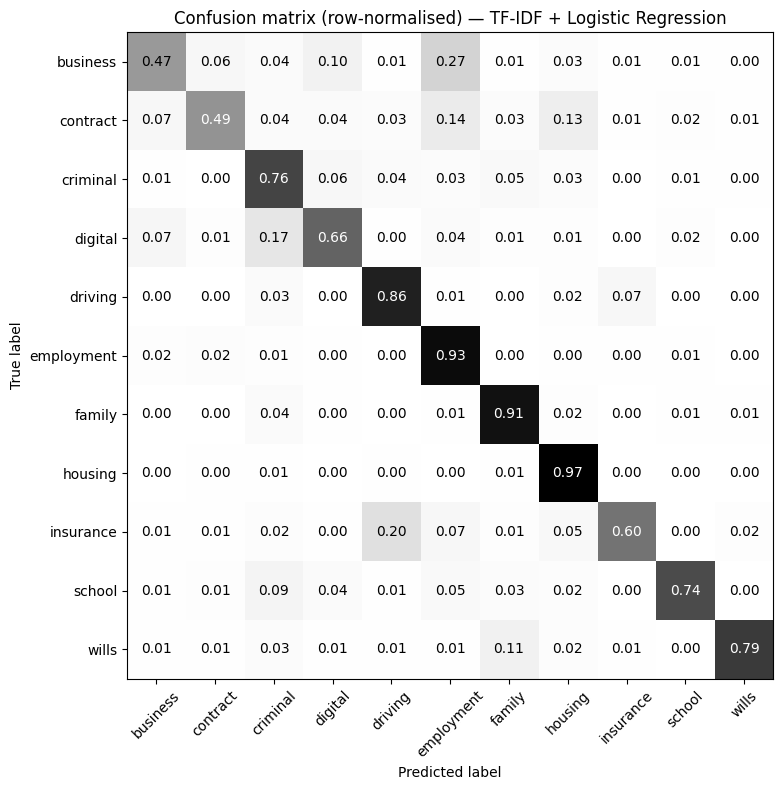

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = sorted(y_train.unique())

cm = confusion_matrix(y_test, y_pred_model, labels=labels, normalize="true")

fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, cmap="Greys", values_format=".2f", colorbar=False, xticks_rotation=45)
ax.set_title("Confusion matrix (row-normalised) — TF-IDF + Logistic Regression")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.4 Prediction confidence and safe routing

Requirements FR-2 and FR-3 state that the classifier must return a confidence
score and that low-confidence predictions must be routed for clarification
rather than guessed at. This matters in a legal application: a confidently
wrong routing can send a user to the wrong body of law, while an admitted
uncertainty costs only a follow-up question.

Logistic regression outputs a probability for every class, so the highest
probability serves as the confidence score. We test two things: whether
confidence is genuinely higher on correct predictions, and what accuracy is
achievable at different thresholds — accepting that a higher threshold means
fewer queries are auto-routed.

In [ ]:
import numpy as np

# Probability for every class, for every test post
probs = model.predict_proba(X_test)

# Confidence = the highest probability the model assigned
top1_conf = probs.max(axis=1)

# Which predictions were actually correct
correct = (y_pred_model == y_test.values)

print(f"Mean confidence when CORRECT:   {top1_conf[correct].mean():.3f}")
print(f"Mean confidence when INCORRECT: {top1_conf[~correct].mean():.3f}")
print()
print("Threshold   Coverage   Accuracy on kept queries")
for t in [0.4, 0.5, 0.6, 0.7, 0.8]:
    keep = top1_conf >= t
    print(f"   {t}       {keep.mean():6.1%}      {correct[keep].mean():.3f}")

Mean confidence when CORRECT:   0.703
Mean confidence when INCORRECT: 0.439

Threshold   Coverage   Accuracy on kept queries
   0.4        78.8%      0.891
   0.5        68.6%      0.914
   0.6        58.6%      0.932
   0.7        48.7%      0.947
   0.8        37.7%      0.960


### 5.5 Model interpretability: most influential terms

Section 4.2 justified logistic regression partly on the grounds that its
learned coefficients can be inspected. We verify that claim here by listing
the ten terms with the highest positive weight for each category.

This matters for a legal application: a prediction that cannot be explained
cannot be audited. If the top terms are legally meaningful, the model is
responding to subject matter rather than to incidental vocabulary.

In [ ]:
# Pull the fitted vectoriser and classifier out of the pipeline
vec = model.named_steps["tfidf"]
clf = model.named_steps["clf"]
feature_names = np.array(vec.get_feature_names_out())

print("Top 10 terms per category\n")
for i, label in enumerate(clf.classes_):
    top = feature_names[np.argsort(clf.coef_[i])[-10:]][::-1]
    print(f"{label:<12} {', '.join(top)}")

Top 10 terms per category

business     business, company, llc, work, sell, store, selling, product, start, paid
contract     contract, agreement, signed, loan, lease, contractor, wedding, cancel, gym, payment
criminal     police, charges, arrested, probation, criminal, assault, crime, charged, jail, theft
digital      online, internet, website, game, computer, copyright, instagram, youtube, video, account
driving      ticket, car, driving, traffic, speeding, parking, license, court, accident, road
employment   employer, work, job, unemployment, employees, boss, fired, employment, hr, working
family       divorce, custody, child, ex, support, kids, father, married, mom, abusive
housing      landlord, apartment, rent, lease, tenant, eviction, house, tenants, property, moved
insurance    insurance, car, accident, policy, medicaid, fault, claim, driver, company, vehicle
school       school, university, class, students, student, college, teacher, grade, campus, semester
wills        estate

### 5.6 Saving the fitted pipeline

The complete pipeline - the fitted TF-IDF vectoriser and the trained
classifier together - is saved as a single file. Saving the whole pipeline
matters: the learned weights are meaningless without the exact vocabulary
they refer to.

The artefact is then reloaded and used on text the model has never seen,
confirming it can be deployed without retraining.

In [ ]:
import joblib

# Save the trained pipeline to a file so it never needs retraining.
# We save the WHOLE pipeline: the weights are meaningless without the
# vocabulary they refer to.
joblib.dump(model, "kimuntu_legal_classifier.joblib")
print("Saved: kimuntu_legal_classifier.joblib")

# Load it back from the file
reloaded = joblib.load("kimuntu_legal_classifier.joblib")

def classify(text):
    """Return the predicted legal category for a new user query."""
    return reloaded.predict([text])[0]

# Prove it works on text it has never seen
print()
print(classify("My landlord refuses to return my security deposit"))
print(classify("I was fired without notice after eight years"))
print(classify("My ex stopped paying child support last month"))
print(classify("Iam looking for a job"))
print(classify("Iam a Ugandan student looking for ways to join US Universities"))
print(classify("Iam a Data Science student looking for schoolarship"))

Saved: kimuntu_legal_classifier.joblib

housing
employment
family
employment
school
school


---

## Summary

**What we built.** A classifier that reads a legal question and predicts its area of law and its the first component of the Kimuntu AI
legal track.

**The data.** Kimuntu's own queries are not yet available, so we used a public
proxy: 98,910 Reddit r/legaladvice posts, each with one of eleven topic
labels. We kept the published splits and removed duplicates within and across
them, so no post was seen twice.

**Results.**

| Model | Accuracy | Macro F1 |
|---|---|---|
| Baseline (always predicts `housing`) | 0.241 | 0.035 |
| TF-IDF + Logistic Regression | **0.822** | **0.761** |

The baseline learns nothing yet scores 24% accuracy — which is why accuracy
alone misleads. Macro F1 improved twenty-one fold. Validation and test agree,
so the model generalises.

**Main finding.** The errors are not random. Business is called employment 27%
of the time, insurance is called driving 20% of the time. Each of these is a
post that genuinely belongs to two categories, but the forum allows only one
label. **Much of our error is label ambiguity in the data, not model failure.**

**Safety.** Confidence is higher when the model is right (0.703) than wrong
(0.439). At a 0.7 threshold, 48.7% of queries route automatically at 94.7%
accuracy; the rest are referred for clarification.

**Limitations.** Proxy data, not Kimuntu's. Mostly US law. No immigration
category, which Kimuntu offers. One label per query. TF-IDF ignores word order.

